<a href="https://colab.research.google.com/github/heisbaed/COU07506_LAB_WEEK_1_230141409381/blob/main/COU07506_Week04_230141409381.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DIGITAL SIGNAL PROCESSING — WEEK 4
## z-Transform, Poles, Zeros and Stability
### Task 4.1 — A Pole-Zero Plotting Function

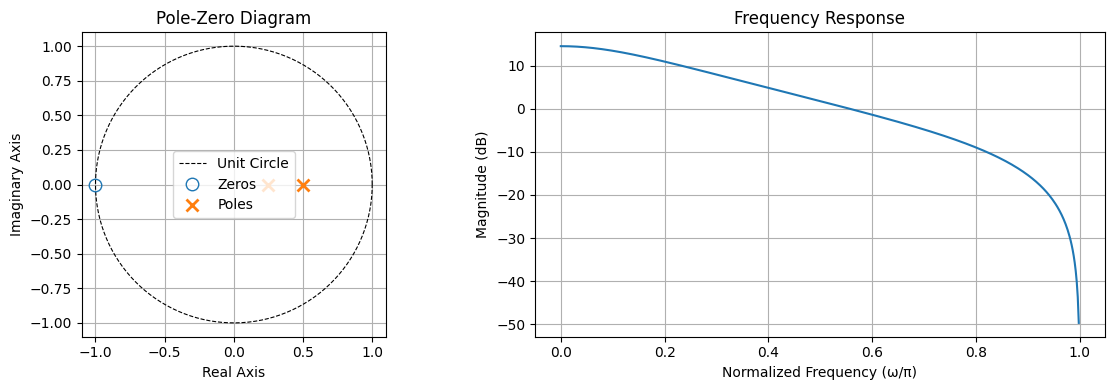

Zeros: [-1.]
Poles: [0.5  0.25]
System Stable: True


In [1]:

# WEEK 4 — TASK 4.1
# Pole-Zero Plotting Function

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Define the pole-zero plotting function
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    # Draw unit circle
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th),
            "k--", lw=0.8, label="Unit Circle")

    # Plot zeros
    ax.plot(z.real, z.imag, "o",
            mfc="none", ms=9, label="Zeros")

    # Plot poles
    ax.plot(p.real, p.imag, "x",
            ms=9, mew=2, label="Poles")

    ax.set_aspect("equal")
    ax.set_xlabel("Real Axis")
    ax.set_ylabel("Imaginary Axis")
    ax.set_title("Pole-Zero Diagram")
    ax.legend()
    ax.grid(True)

    return z, p

# System coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Create two graphs
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 4)
)

# Graph 1: Pole-zero diagram
z, p = zplane(b, a, ax1)

# Graph 2: Frequency response
w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_title("Frequency Response")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)

plt.tight_layout()
plt.show()

# Display system information
print("Zeros:", z)
print("Poles:", p)
print("System Stable:", np.all(np.abs(p) < 1))


### Task 4.1 — Observation and Discussion

The pole-zero diagram shows one zero at z = −1 and two poles at z = 0.5 and z = 0.25.

Both poles lie inside the unit circle, meaning their magnitudes are less than 1.

The frequency-response graph shows how the system gain varies with frequency.

**Stability:** The system is stable because all poles lie strictly inside the unit circle.

**Conclusion:** Pole-zero analysis provides a useful method for determining the stability and frequency characteristics of a digital system.

## Task 4.2 — Inverse z-Transform with residuez

SYSTEM 1
Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Partial fractions: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
lfilter: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Results match: True

SYSTEM 2
Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Partial fractions: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Theory: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Results match: True
Matches theory: True


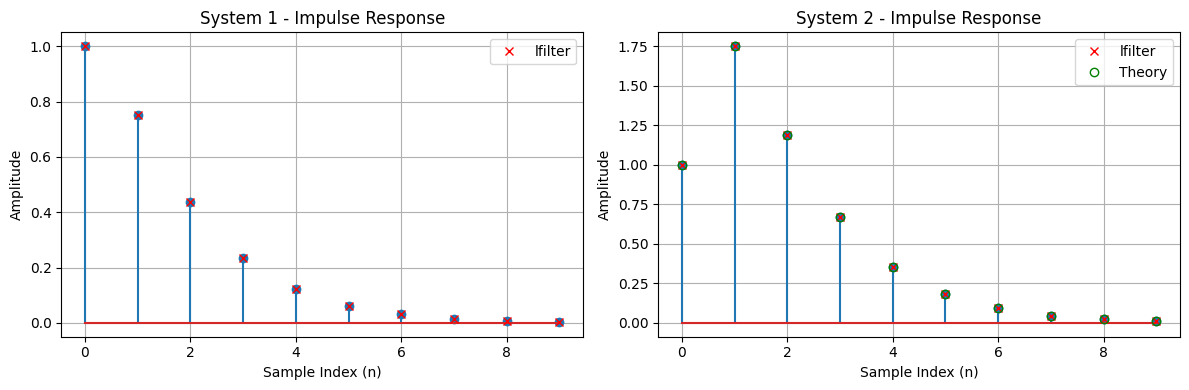

In [2]:

# WEEK 4 — TASK 4.2
# Inverse z-Transform with Partial Fractions

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Sample indices
n = np.arange(10)

# Unit impulse
impulse = np.zeros(10)
impulse[0] = 1

# SYSTEM 1
b1 = [1]
a = [1, -0.75, 0.125]

# Partial fraction decomposition
r1, p1, k1 = signal.residuez(b1, a)

print("SYSTEM 1")
print("Residues:", r1)
print("Poles:", p1)

# Inverse z-transform using partial fractions
h1_pf = sum(
    ri * pi**n for ri, pi in zip(r1, p1)
).real

# Compare with lfilter
h1_lf = signal.lfilter(b1, a, impulse)

print("Partial fractions:", h1_pf)
print("lfilter:", h1_lf)
print("Results match:",
      np.allclose(h1_pf, h1_lf))

# SYSTEM 2 — Task 4.1 System
b2 = [1, 1]

r2, p2, k2 = signal.residuez(b2, a)

print("\nSYSTEM 2")
print("Residues:", r2)
print("Poles:", p2)

h2_pf = sum(
    ri * pi**n for ri, pi in zip(r2, p2)
).real

h2_lf = signal.lfilter(b2, a, impulse)

# Theoretical closed-form expression
h2_theory = 6*(0.5**n) - 5*(0.25**n)

print("Partial fractions:", h2_pf)
print("lfilter:", h2_lf)
print("Theory:", h2_theory)

print("Results match:",
      np.allclose(h2_pf, h2_lf))

print("Matches theory:",
      np.allclose(h2_pf, h2_theory))

# Plot both impulse responses
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].stem(n, h1_pf)
axes[0].plot(n, h1_lf, "rx", label="lfilter")
axes[0].set_title("System 1 - Impulse Response")
axes[0].set_xlabel("Sample Index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

axes[1].stem(n, h2_pf)
axes[1].plot(n, h2_lf, "rx", label="lfilter")
axes[1].plot(n, h2_theory, "go",
             fillstyle="none", label="Theory")
axes[1].set_title("System 2 - Impulse Response")
axes[1].set_xlabel("Sample Index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Task 4.2 — Observation and Discussion

The inverse z-transform was calculated using SciPy's `residuez()` function and verified using `lfilter()`.

For the first system, the partial-fraction decomposition produced poles at 0.5 and 0.25, with corresponding residues of 2 and −1.

For the second system, the residues were 6 and −5, corresponding to poles at 0.5 and 0.25, respectively.

The impulse responses obtained using partial fractions matched the results from `lfilter()`.

The second system also agreed with the theoretical expression:

h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, for n ≥ 0.

**Conclusion:** Partial-fraction decomposition is an effective method for calculating inverse z-transforms. The results agree with the numerical filtering method.

## Task 4.3 — Pole Position and the Impulse Response

r = 0.5
Poles: [0.3536+0.3536j 0.3536-0.3536j]
BIBO Stable: True
----------------------------
r = 0.8
Poles: [0.5657+0.5657j 0.5657-0.5657j]
BIBO Stable: True
----------------------------
r = 0.95
Poles: [0.6718+0.6718j 0.6718-0.6718j]
BIBO Stable: True
----------------------------
r = 1.0
Poles: [0.7071+0.7071j 0.7071-0.7071j]
BIBO Stable: False
----------------------------
r = 1.05
Poles: [0.7425+0.7425j 0.7425-0.7425j]
BIBO Stable: False
----------------------------


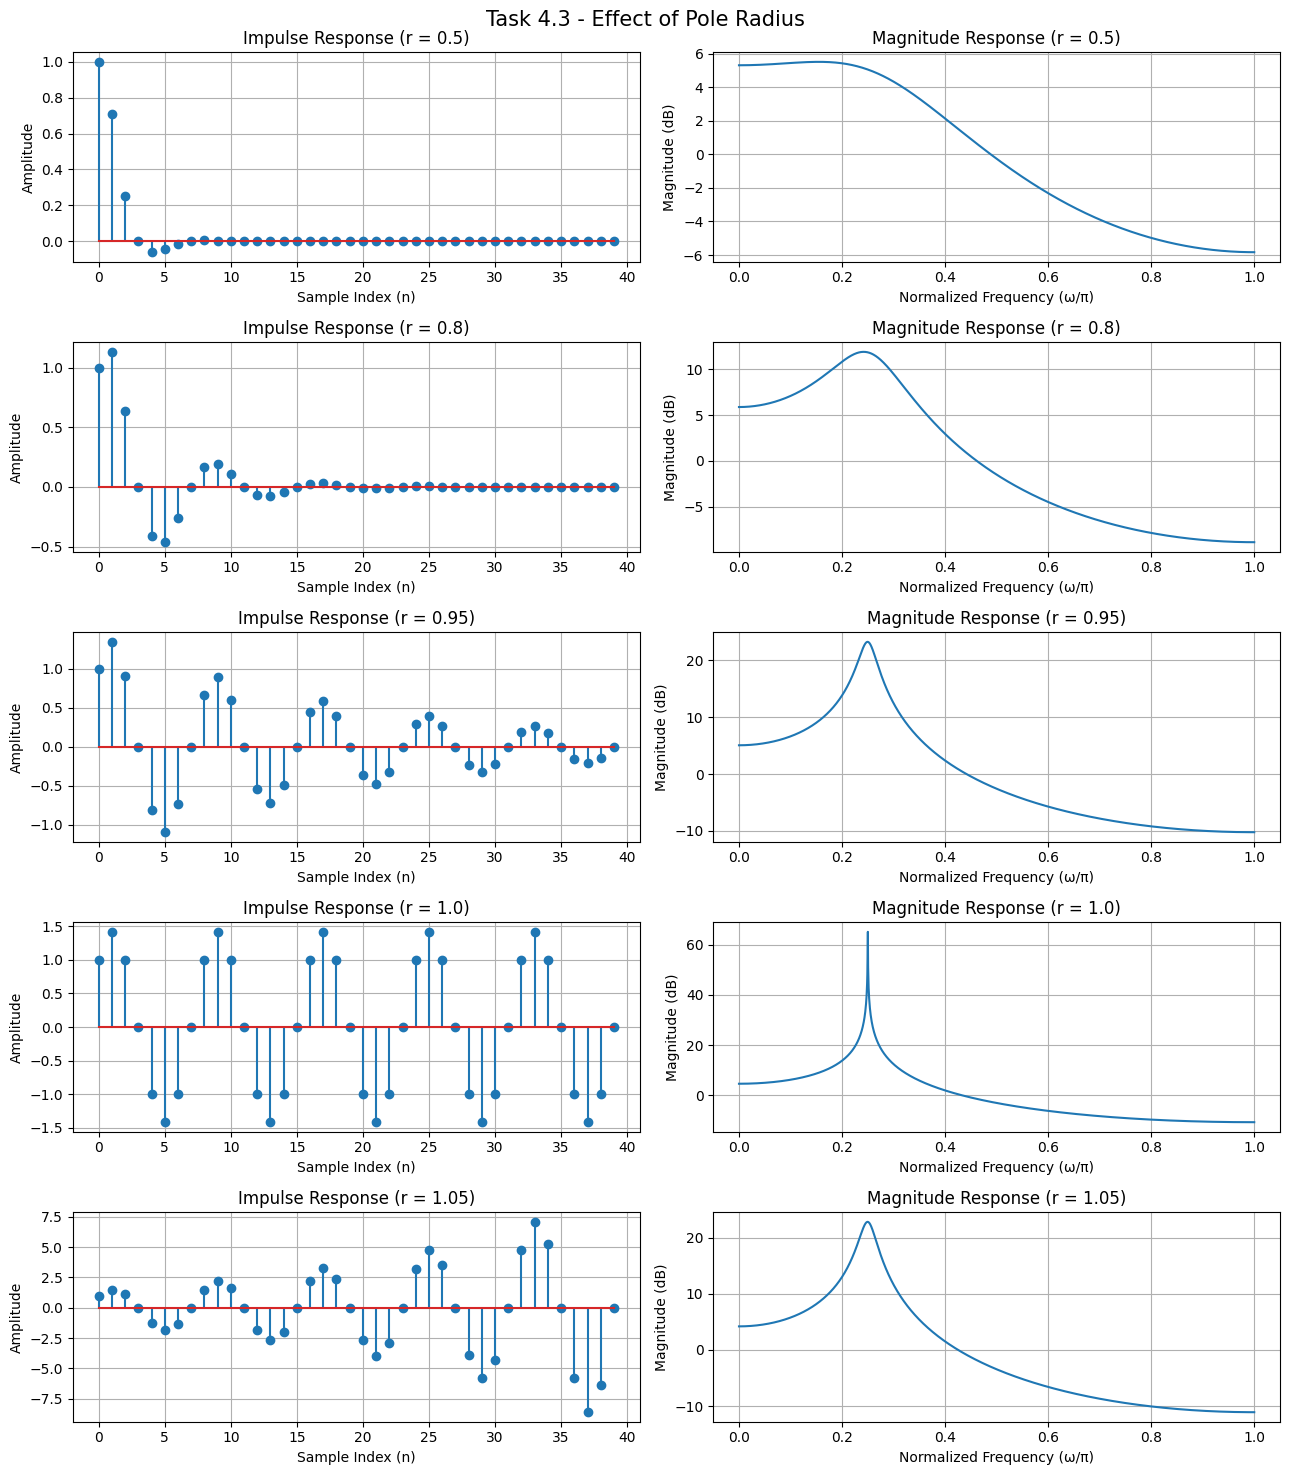

In [3]:

# WEEK 4 — TASK 4.3
# Pole Position and Impulse Response

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Pole radius values
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

# Resonance angle
theta = np.pi / 4

# 40 samples
n = np.arange(40)

# Unit impulse
impulse = np.zeros(40)
impulse[0] = 1

# Frequency points (avoid exact pole angle)
w = np.linspace(0, np.pi, 2000)

# Create plots
fig, axes = plt.subplots(
    5, 2, figsize=(13, 15)
)

for i, r in enumerate(r_values):

    # Numerator and denominator
    b = [1]
    a = [1, -2*r*np.cos(theta), r**2]

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Calculate frequency response
    _, H = signal.freqz(b, a, worN=w)

    magnitude_db = 20*np.log10(
        np.maximum(np.abs(H), 1e-12)
    )

    # Plot impulse response
    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(
        f"Impulse Response (r = {r})"
    )
    axes[i, 0].set_xlabel("Sample Index (n)")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid(True)

    # Plot magnitude response
    axes[i, 1].plot(w/np.pi, magnitude_db)
    axes[i, 1].set_title(
        f"Magnitude Response (r = {r})"
    )
    axes[i, 1].set_xlabel(
        "Normalized Frequency (ω/π)"
    )
    axes[i, 1].set_ylabel("Magnitude (dB)")
    axes[i, 1].grid(True)

    # Display stability
    poles = np.roots(a)
    stable = np.all(np.abs(poles) < 1)

    print(f"r = {r}")
    print("Poles:", np.round(poles, 4))
    print("BIBO Stable:", stable)
    print("----------------------------")

plt.suptitle(
    "Task 4.3 - Effect of Pole Radius",
    fontsize=15
)
plt.tight_layout()
plt.show()


### Task 4.3 — Observation and Discussion

The effect of pole radius on the impulse response and frequency response was investigated using five different radius values.

**1. Radius r = 0.5**

The impulse response decays rapidly toward zero. The resonance peak is relatively broad, and the system is stable.

**2. Radius r = 0.8**

The impulse response decays more slowly than at r = 0.5. The resonance becomes stronger and narrower. The system remains stable.

**3. Radius r = 0.95**

The impulse response exhibits slowly decaying oscillations. The resonance peak becomes sharper because the poles are closer to the unit circle. The system is stable.

**4. Radius r = 1.0**

The impulse response produces sustained oscillations without decaying toward zero. The poles lie exactly on the unit circle, so the system is not BIBO stable.

**5. Radius r = 1.05**

The impulse response grows in amplitude because the poles are outside the unit circle. The system is unstable.

**Conclusion:**

As the pole radius increases toward 1 from below, the impulse response decays more slowly and the resonance becomes sharper and narrower.

For a causal system, poles strictly inside the unit circle produce a stable response, while poles on or outside the unit circle make this system BIBO unstable.

## Task 4.4 — Stability of Given Systems


SYSTEM H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.9434 0.9434]
BIBO Stable: True
----------------------------

SYSTEM H2
Zeros: [-1.]
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
BIBO Stable: False
----------------------------

SYSTEM H3
Zeros: []
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
BIBO Stable: False
----------------------------

SYSTEM H4
Zeros: [-1.+0.j  0.+1.j  0.-1.j  1.+0.j]
Poles: []
Pole magnitudes: []
BIBO Stable: True
----------------------------


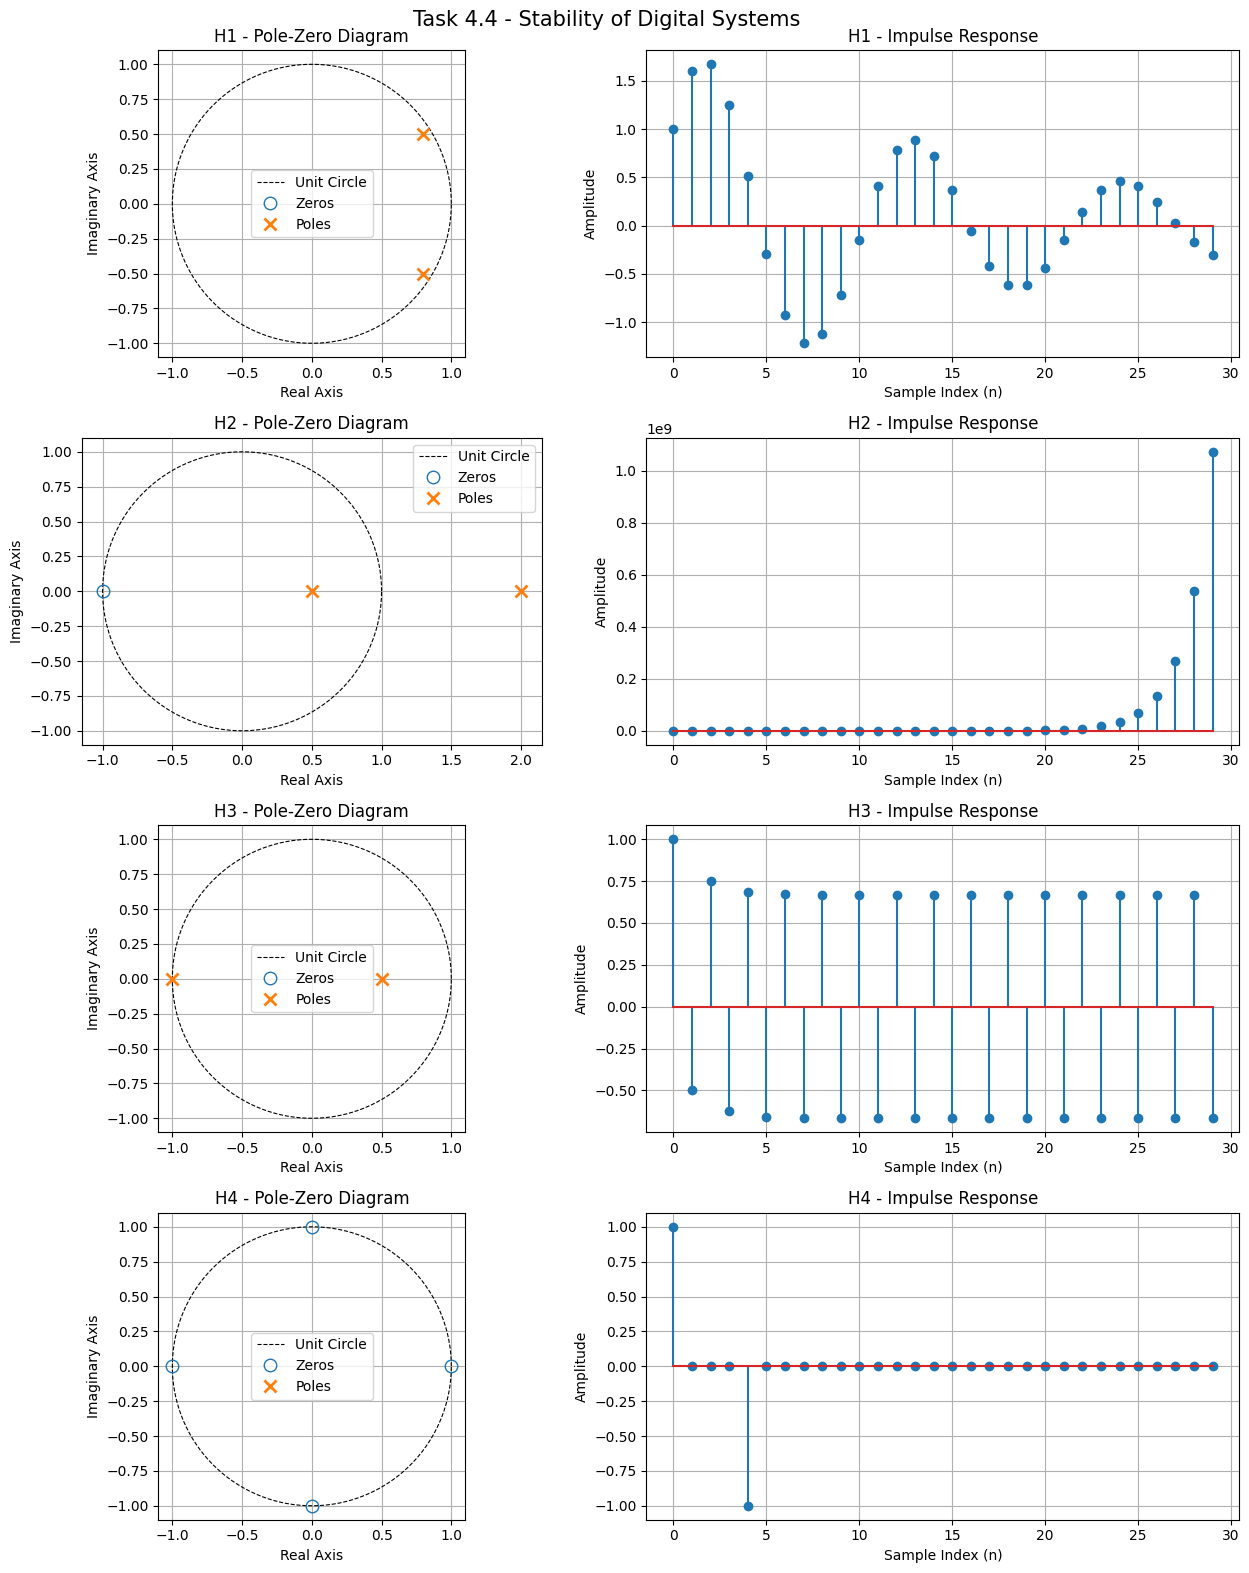

In [4]:

# WEEK 4 — TASK 4.4
# Stability of Given Systems

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Four systems from the laboratory manual
systems = {
    "H1": {
        "b": [1],
        "a": [1, -1.6, 0.89]
    },
    "H2": {
        "b": [1, 1],
        "a": [1, -2.5, 1]
    },
    "H3": {
        "b": [1],
        "a": [1, 0.5, -0.5]
    },
    "H4": {
        "b": [1, 0, 0, 0, -1],
        "a": [1]
    }
}

# Generate unit impulse
n = np.arange(30)
impulse = np.zeros(30)
impulse[0] = 1

# Create plots
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for i, (name, sys) in enumerate(systems.items()):

    b = sys["b"]
    a = sys["a"]

    # Pole-zero diagram using Task 4.1 function
    zeros, poles = zplane(b, a, axes[i, 0])

    axes[i, 0].set_title(
        f"{name} - Pole-Zero Diagram"
    )

    # Determine stability
    stable = np.all(np.abs(poles) < 1 - 1e-10)

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Plot impulse response
    axes[i, 1].stem(n, h)
    axes[i, 1].set_title(
        f"{name} - Impulse Response"
    )
    axes[i, 1].set_xlabel("Sample Index (n)")
    axes[i, 1].set_ylabel("Amplitude")
    axes[i, 1].grid(True)

    # Print results
    print(f"\nSYSTEM {name}")
    print("Zeros:", np.round(zeros, 4))
    print("Poles:", np.round(poles, 4))
    print("Pole magnitudes:",
          np.round(np.abs(poles), 4))
    print("BIBO Stable:", stable)
    print("----------------------------")

plt.suptitle(
    "Task 4.4 - Stability of Digital Systems",
    fontsize=15
)
plt.tight_layout()
plt.show()


### Task 4.4 — Observation and Discussion

Four digital systems were analyzed using pole-zero diagrams and impulse responses.

**System H1:** The poles are located at 0.8 ± 0.5j. Their magnitudes are approximately 0.9434, which is less than 1. The impulse response decays toward zero, indicating that the system is stable.

**System H2:** The poles are at 2 and 0.5. Since one pole lies outside the unit circle, the impulse response grows, making the system unstable.

**System H3:** The poles are at −1 and 0.5. The pole at −1 lies exactly on the unit circle. The impulse response contains a sustained oscillation and is not absolutely summable. Therefore, the system is not BIBO stable.

**System H4:** The system has no poles and has a finite impulse response with nonzero values only at n = 0 and n = 4. Therefore, it is stable.

**Conclusion:**

The stability of a causal digital system can be determined by examining its poles. For the systems tested, H1 and H4 are stable, while H2 and H3 are unstable.

## Task 4.5 — Design a Resonator

Resonator Design
-------------------------
Sampling Frequency: 8000 Hz
Target Frequency: 1000 Hz
Pole Radius: 0.97
Zeros: [-1.  1.]
Poles: [0.6859+0.6859j 0.6859-0.6859j]
System Stable: True
Peak Frequency: 1000.98 Hz


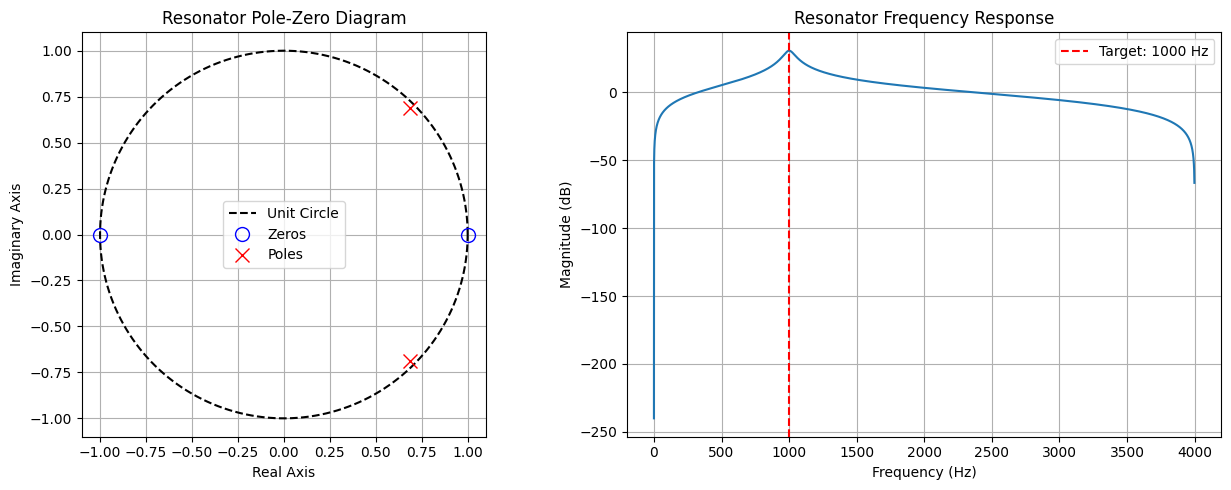

In [5]:

# WEEK 4 — TASK 4.5
# Design a Digital Resonator

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# Design specifications
fs = 8000
f0 = 1000
r = 0.97

# Resonance angle
theta = 2 * np.pi * f0 / fs

# Zeros at z = +1 and z = -1
b = [1, 0, -1]

# Poles at r * exp(+/-j*theta)
a = [1, -2*r*np.cos(theta), r**2]

# Calculate zeros and poles
zeros, poles, gain = signal.tf2zpk(b, a)

print("Resonator Design")
print("-------------------------")
print("Sampling Frequency:", fs, "Hz")
print("Target Frequency:", f0, "Hz")
print("Pole Radius:", r)
print("Zeros:", np.round(zeros, 4))
print("Poles:", np.round(poles, 4))

stable = np.all(np.abs(poles) < 1)
print("System Stable:", stable)

# Frequency response
f, H = signal.freqz(b, a, worN=4096, fs=fs)

magnitude_db = 20*np.log10(
    np.maximum(np.abs(H), 1e-12)
)

peak_frequency = f[np.argmax(np.abs(H))]
print(f"Peak Frequency: {peak_frequency:.2f} Hz")

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot unit circle
t = np.linspace(0, 2*np.pi, 400)
axes[0].plot(np.cos(t), np.sin(t),
             "k--", label="Unit Circle")

# Plot zeros and poles
axes[0].plot(zeros.real, zeros.imag,
             "bo", fillstyle="none",
             markersize=10, label="Zeros")

axes[0].plot(poles.real, poles.imag,
             "rx", markersize=10,
             label="Poles")

axes[0].set_title("Resonator Pole-Zero Diagram")
axes[0].set_xlabel("Real Axis")
axes[0].set_ylabel("Imaginary Axis")
axes[0].set_aspect("equal")
axes[0].legend()
axes[0].grid(True)

# Plot frequency response
axes[1].plot(f, magnitude_db)
axes[1].axvline(f0, color="red",
                linestyle="--",
                label="Target: 1000 Hz")

axes[1].set_title("Resonator Frequency Response")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude (dB)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


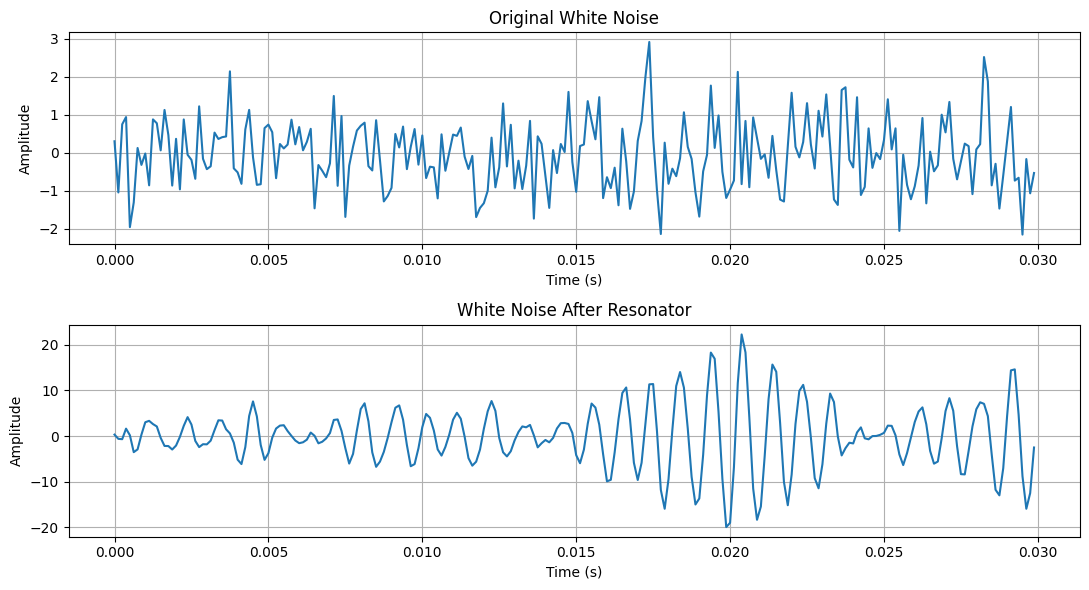

Original White Noise:


Filtered Noise - 1000 Hz Resonator:



Task 4.5 Completed Successfully!


In [6]:

# TASK 4.5 — Apply Resonator to White Noise

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# Generate 2 seconds of white noise
rng = np.random.default_rng(42)

duration = 2
n = np.arange(fs * duration)
t = n / fs

x = rng.standard_normal(len(n))

# Apply resonator
y = signal.lfilter(b, a, x)

# Plot first 30 milliseconds
N = int(0.03 * fs)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))

axes[0].plot(t[:N], x[:N])
axes[0].set_title("Original White Noise")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlabel("Time (s)")
axes[0].grid(True)

axes[1].plot(t[:N], y[:N])
axes[1].set_title("White Noise After Resonator")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Listen to original noise
print("Original White Noise:")
display(Audio(x, rate=fs))

# Listen to filtered noise
print("Filtered Noise - 1000 Hz Resonator:")
display(Audio(y, rate=fs))

print("\nTask 4.5 Completed Successfully!")


### Task 4.5 — Observation and Discussion

A digital resonator was designed with a target resonance frequency of 1,000 Hz, a sampling frequency of 8,000 Hz, and a pole radius of 0.97.

The poles were positioned near the unit circle at angles corresponding to the target frequency.

Two zeros were placed at z = +1 and z = −1 to suppress the DC component (0 Hz) and the Nyquist frequency (4,000 Hz).

The frequency-response graph showed a sharp resonance near 1,000 Hz.

**Stability:**

The resonator is stable because both poles have a magnitude of 0.97, which is less than 1.

**White Noise Filtering:**

The original white noise contained a broad range of frequencies.

After passing through the resonator, frequencies near 1,000 Hz were emphasized while other frequencies were attenuated relative to the resonance.

The filtered audio should have a more tonal or ringing sound compared with the original noise.

**Conclusion:**

A digital resonator can selectively emphasize frequencies near a desired frequency by positioning its poles near the unit circle. The pole radius determines resonance sharpness and stability.

# WEEK 4 — PRE-LAB AND ANALYSIS QUESTIONS

## A. Pre-Lab Questions

### Question 1: Find the poles of H(z) = 1/(1 − 0.9z⁻¹ + 0.81z⁻²) and determine whether the system is stable.

**Answer:**

The poles are obtained by solving the denominator equation:

z² − 0.9z + 0.81 = 0

Using the quadratic formula:

z = (0.9 ± √(0.81 − 3.24))/2

The resulting poles are:

- p₁ = 0.45 + 0.7794j
- p₂ = 0.45 − 0.7794j

The magnitude of each pole is 0.9.

Since both poles lie strictly inside the unit circle (|p| < 1), the causal system is **stable**.

### Question 2: Write the partial-fraction expansion of X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)].

**Answer:**

Expressing the function in partial fractions:

X(z) = A/(1 − 0.5z⁻¹) + B/(1 − 0.25z⁻¹)

Solving for the constants gives:

A = 2 and B = −1

Therefore:

**X(z) = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹)**

For the causal sequence, the inverse z-transform is:

x(n) = [2(0.5)ⁿ − (0.25)ⁿ]u(n)

---

## B. Analysis Questions

### Question 1: Explain the effect of pole radius r on the bandwidth of resonance in Task 4.3.

**Answer:**

The pole radius determines how quickly the impulse response decays and how sharp the resonance becomes.

For smaller pole radii, the impulse response decays rapidly and the resonance has a wider bandwidth.

As the pole radius approaches 1 from below, the impulse response decays more slowly, producing a sharper resonance with a narrower bandwidth.

Therefore, increasing r toward 1 improves frequency selectivity but reduces the decay rate of the impulse response.

### Question 2: What happens to h(n) when a pole lies exactly on the unit circle?

**Answer:**

When a simple pole lies exactly on the unit circle, its contribution to the impulse response does not decay.

For a complex-conjugate pole pair on the unit circle, the impulse response exhibits sustained oscillations.

Since the impulse response is not absolutely summable, the causal system is not Bounded-Input Bounded-Output (BIBO) stable.



Question 3: Why does placing zeros at z = ±1 make the resonator a band-pass filter?

Answer:

Placing zeros at z = +1 and z = −1 produces zero gain at two frequencies:

z = +1 corresponds to 0 Hz (DC).

z = −1 corresponds to the Nyquist frequency, fs/2.

In Task 4.5, the sampling rate is 8,000 Hz, so the Nyquist frequency is 4,000 Hz.

These zeros suppress the frequencies at 0 Hz and 4,000 Hz.

The poles are positioned near the frequency of 1,000 Hz, creating a strong resonance around that frequency.

Therefore, the system has a band-pass response, emphasizing frequencies around 1,000 Hz while suppressing DC and Nyquist-frequency components.

Question 4: Use the stability triangle to check the answers to Task 4.4 (a)–(c).

Answer:

For a second-order causal system with denominator:

A(z) = 1 + a₁z⁻¹ + a₂z⁻²

The stability triangle requires:

|a₂| < 1

1 + a₁ + a₂ > 0

1 − a₁ + a₂ > 0

System H1

Denominator: 1 − 1.6z⁻¹ + 0.89z⁻²

a₁ = −1.6, a₂ = 0.89

|0.89| < 1 — Satisfied

1 − 1.6 + 0.89 = 0.29 > 0 — Satisfied

1 + 1.6 + 0.89 = 3.49 > 0 — Satisfied

Result: H1 is stable.

System H2

Denominator: 1 − 2.5z⁻¹ + z⁻²

a₁ = −2.5, a₂ = 1

|1| < 1 — Not satisfied

1 − 2.5 + 1 = −0.5 — Not satisfied

1 + 2.5 + 1 = 4.5 > 0 — Satisfied

Result: H2 is unstable.

System H3

Denominator: 1 + 0.5z⁻¹ − 0.5z⁻²

a₁ = 0.5, a₂ = −0.5

|−0.5| < 1 — Satisfied

1 + 0.5 − 0.5 = 1 > 0 — Satisfied

1 − 0.5 − 0.5 = 0 — Not satisfied

Result: H3 is not BIBO stable, because one pole lies on the unit circle.

Conclusion:

The stability triangle confirms the pole-zero analysis from Task 4.4. H1 is stable, while H2 and H3 are not stable.

C. AI-Use Statement

I used ChatGPT (OpenAI) to assist with understanding z-transforms, pole-zero analysis, inverse z-transforms, system stability, and digital resonator design.

The tool assisted with Python code preparation, debugging explanations, and understanding the mathematical concepts used in the laboratory.

I executed the code in Google Colab and checked the generated plots and numerical outputs against the expected theoretical results, including pole locations, stability classifications, and impulse responses.

The results and explanations were reviewed as part of the laboratory exercise.